# Customer Churn Analysis
**Dataset:** `Training_dataset_for_customer_churn.csv` (64,374 subscription customers)

> **Note on the brief:** the task steps mention learning hours, completion rate, satisfaction score and device/platform. The supplied file is a *subscription churn* dataset and contains none of those columns, so each step is mapped to its closest churn equivalent:
> engagement = Usage Frequency / Last Interaction, completion/retention = Churn (inverse), satisfaction proxies = Support Calls and Total Spend, platform = Subscription Type / Contract Length.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import os
sns.set_theme(style='whitegrid', palette='deep')
os.makedirs('figures', exist_ok=True)
PALETTE = {'churn':'#C44E52','base':'#4C72B0'}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=110, bbox_inches='tight')
    plt.show()

def annotate(ax, fmt='{:.0%}'):
    for p in ax.patches:
        ax.annotate(fmt.format(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)


## Step 1 – Dataset Understanding

In [2]:
df = pd.read_csv('Training_dataset_for_customer_churn.csv')
print('Rows x Columns:', df.shape)
print('\nData types:')
print(df.dtypes.to_string())
print('\nFirst 5 rows:')
print(df.head().to_string(index=False))
print('\nNumeric summary:')
print(df.describe().T.round(2).to_string())


Rows x Columns: (64374, 12)

Data types:
CustomerID           int64
Age                  int64
Gender                 str
Tenure               int64
Usage Frequency      int64
Support Calls        int64
Payment Delay        int64
Subscription Type      str
Contract Length        str
Total Spend          int64
Last Interaction     int64
Churn                int64

First 5 rows:
 CustomerID  Age Gender  Tenure  Usage Frequency  Support Calls  Payment Delay Subscription Type Contract Length  Total Spend  Last Interaction  Churn
          1   22 Female      25               14              4             27             Basic         Monthly          598                 9      1
          2   41 Female      28               28              7             13          Standard         Monthly          584                20      0
          3   47   Male      27               10              2             29           Premium          Annual          757                21      0
          4   35

**Understanding.** 64,374 rows × 12 columns. Numeric: CustomerID, Age, Tenure, Usage Frequency, Support Calls, Payment Delay, Total Spend, Last Interaction, Churn. Categorical: Gender, Subscription Type, Contract Length.
Behavioural attributes: **Usage Frequency, Support Calls, Payment Delay, Last Interaction, Tenure, Total Spend**. Target: **Churn** (1 = churned).

## Step 2 – Data Preparation

In [3]:
print('Missing values per column:')
print(df.isna().sum().to_string())
print('\nDuplicate rows:', df.duplicated().sum())
print('Duplicate CustomerIDs:', df.CustomerID.duplicated().sum())

# Convert to appropriate types
for c in ['Gender','Subscription Type','Contract Length']:
    df[c] = df[c].astype('category')
df['Churn'] = df['Churn'].astype(int)

# Consistency checks
print('\nAge range:', df.Age.min(), '-', df.Age.max())
print('Negative values in numeric columns:', int((df.select_dtypes('number') < 0).sum().sum()))
print('Churn values:', sorted(df.Churn.unique()))
print('\nCategory levels:')
for c in ['Gender','Subscription Type','Contract Length']:
    print(' ', c, list(df[c].cat.categories))

# Data-quality flag: is the row order meaningful?
order_check = df.groupby(pd.cut(df.CustomerID, [0,20000,40000,64374]), observed=True).Churn.mean().round(3)
print('\nChurn rate by CustomerID block (should be flat if random):')
print(order_check.to_string())


Missing values per column:
CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0

Duplicate rows: 0
Duplicate CustomerIDs: 0

Age range: 18 - 65
Negative values in numeric columns: 0
Churn values: [np.int64(0), np.int64(1)]

Category levels:
  Gender ['Female', 'Male']
  Subscription Type ['Basic', 'Premium', 'Standard']
  Contract Length ['Annual', 'Monthly', 'Quarterly']

Churn rate by CustomerID block (should be flat if random):
CustomerID
(0, 20000]        0.259
(20000, 40000]    0.256
(40000, 64374]    0.828


**Result.** No missing values, duplicates or invalid ranges; types are now appropriate.
**Data-quality warning:** churn is ~26% for IDs ≤ 40,000 but ~83% above that, so the file appears to be two stacked datasets. `CustomerID` is excluded from all analysis and modelling.

## Step 3 – Exploratory Data Analysis

Users by age group:
Age Group
18-25    0.161
26-35    0.203
36-45    0.204
46-55    0.213
56-65    0.219

Gender:
Gender
Female    0.534
Male      0.466

Subscription type:
Subscription Type
Standard    0.334
Basic       0.333
Premium     0.333

Contract length:
Contract Length
Monthly      0.344
Annual       0.333
Quarterly    0.324

Overall churn rate: 47.4%


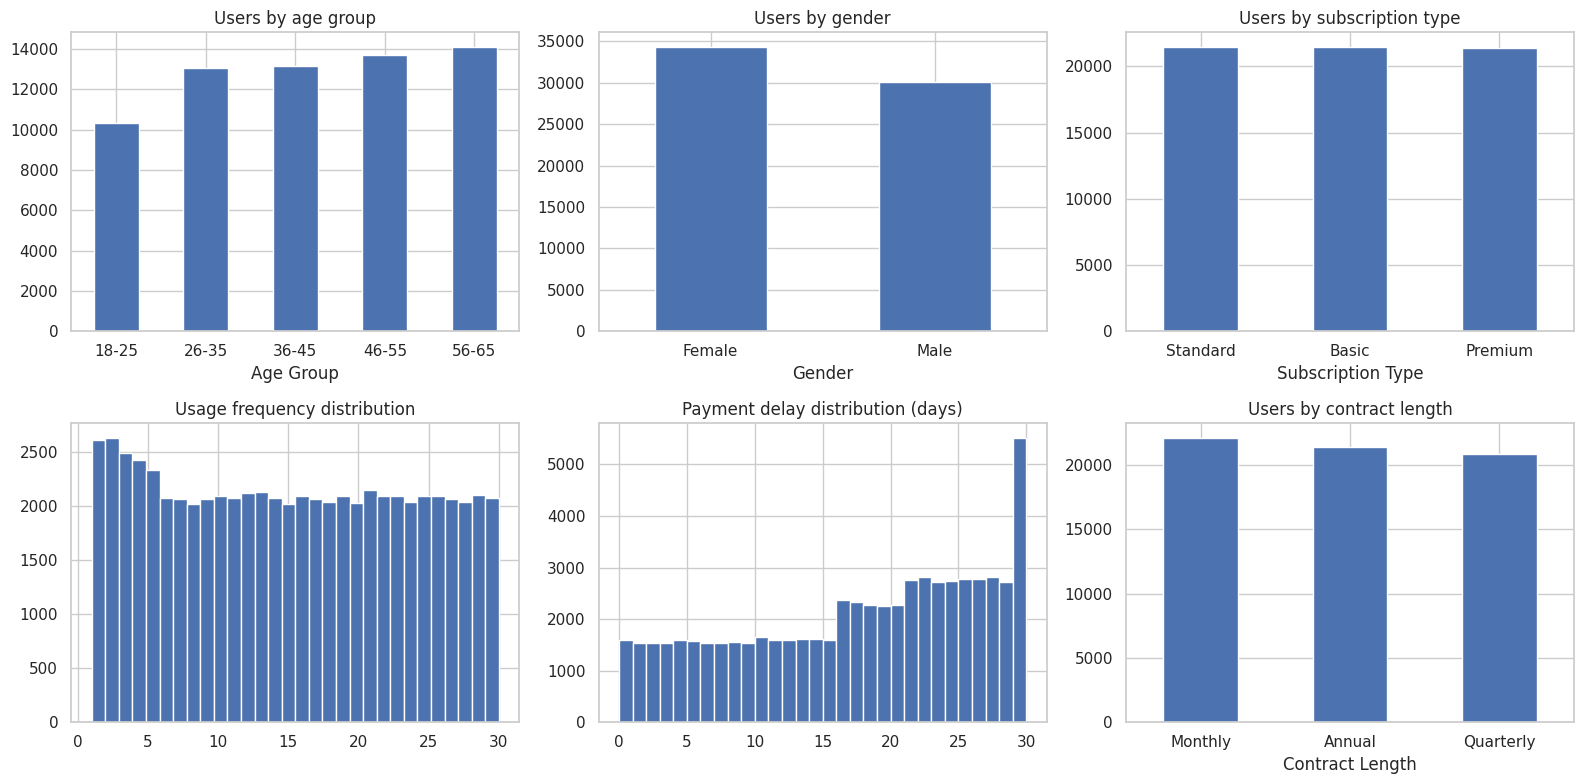

In [4]:
df['Age Group'] = pd.cut(df.Age, [17,25,35,45,55,65], labels=['18-25','26-35','36-45','46-55','56-65'])
df['Usage Band'] = pd.cut(df['Usage Frequency'], [0,10,20,30], labels=['Low (1-10)','Medium (11-20)','High (21-30)'])
df['Delay Band'] = pd.cut(df['Payment Delay'], [-1,10,20,30], labels=['0-10 days','11-20 days','21-30 days'])
df['Support Band'] = pd.cut(df['Support Calls'], [-1,2,4,6,10], labels=['0-2','3-4','5-6','7-10'])
df['Tenure Band'] = pd.cut(df.Tenure, [0,12,24,36,48,60], labels=['1-12','13-24','25-36','37-48','49-60'])

print('Users by age group:'); print(df['Age Group'].value_counts(normalize=True).sort_index().round(3).to_string())
print('\nGender:'); print(df.Gender.value_counts(normalize=True).round(3).to_string())
print('\nSubscription type:'); print(df['Subscription Type'].value_counts(normalize=True).round(3).to_string())
print('\nContract length:'); print(df['Contract Length'].value_counts(normalize=True).round(3).to_string())
print('\nOverall churn rate: {:.1%}'.format(df.Churn.mean()))

fig, ax = plt.subplots(2,3, figsize=(16,8))
df['Age Group'].value_counts().sort_index().plot.bar(ax=ax[0,0], color=PALETTE['base'], rot=0); ax[0,0].set_title('Users by age group')
df.Gender.value_counts().plot.bar(ax=ax[0,1], color=PALETTE['base'], rot=0); ax[0,1].set_title('Users by gender')
df['Subscription Type'].value_counts().plot.bar(ax=ax[0,2], color=PALETTE['base'], rot=0); ax[0,2].set_title('Users by subscription type')
ax[1,0].hist(df['Usage Frequency'], bins=30, color=PALETTE['base']); ax[1,0].set_title('Usage frequency distribution')
ax[1,1].hist(df['Payment Delay'], bins=30, color=PALETTE['base']); ax[1,1].set_title('Payment delay distribution (days)')
df['Contract Length'].value_counts().plot.bar(ax=ax[1,2], color=PALETTE['base'], rot=0); ax[1,2].set_title('Users by contract length')
save_fig('01_user_distributions')


**Observations.** Ages are spread evenly with a slight skew to 46-65. 53% of users are female. Subscription and contract types are almost perfectly balanced. Usage frequency and payment delay are roughly uniform. Overall churn is 47%.

## Step 4 – Engagement Analysis

Average usage frequency by age group:
Age Group
18-25    15.44
26-35    15.45
36-45    15.21
46-55    14.78
56-65    14.64

Average usage frequency by subscription type:
Subscription Type
Basic       15.08
Premium     15.08
Standard    15.07

Average usage frequency by contract length:
Contract Length
Annual       14.91
Monthly      15.18
Quarterly    15.15

Average usage frequency by gender:
Gender
Female    15.14
Male      15.02

Churn rate by usage band:
                 size   mean
Usage Band                  
Low (1-10)      22812  0.550
Medium (11-20)  20740  0.432
High (21-30)    20822  0.432

Correlation usage vs churn: -0.115
Correlation last-interaction vs churn: -0.003


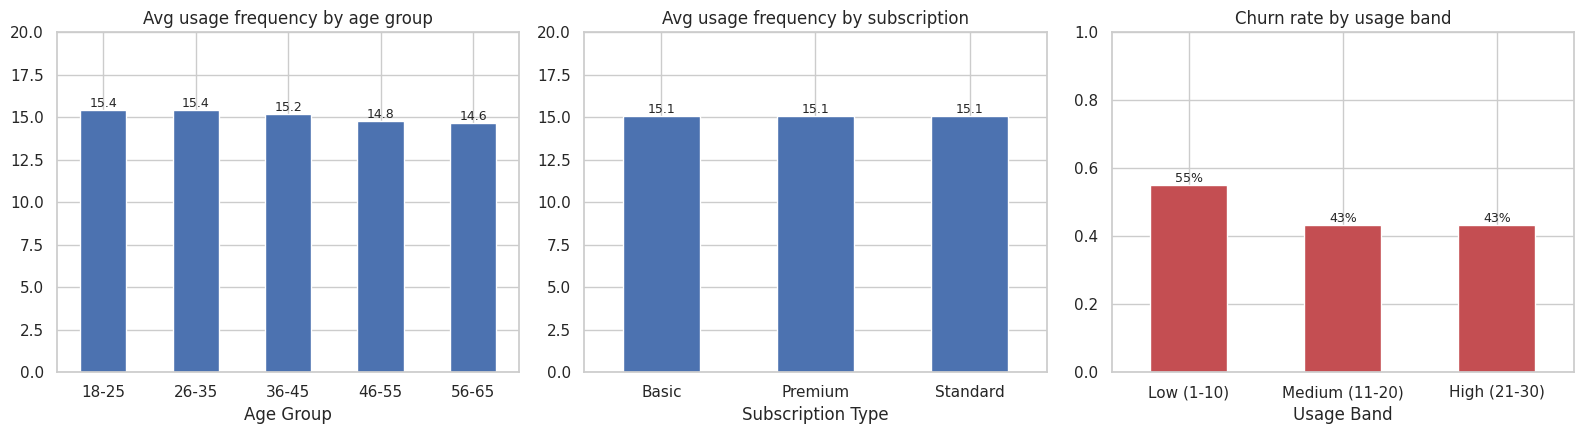

In [5]:
print('Average usage frequency by age group:')
print(df.groupby('Age Group', observed=True)['Usage Frequency'].mean().round(2).to_string())
print('\nAverage usage frequency by subscription type:')
print(df.groupby('Subscription Type', observed=True)['Usage Frequency'].mean().round(2).to_string())
print('\nAverage usage frequency by contract length:')
print(df.groupby('Contract Length', observed=True)['Usage Frequency'].mean().round(2).to_string())
print('\nAverage usage frequency by gender:')
print(df.groupby('Gender', observed=True)['Usage Frequency'].mean().round(2).to_string())
print('\nChurn rate by usage band:')
print(df.groupby('Usage Band', observed=True).Churn.agg(['size','mean']).round(3).to_string())
print('\nCorrelation usage vs churn: {:.3f}'.format(df['Usage Frequency'].corr(df.Churn)))
print('Correlation last-interaction vs churn: {:.3f}'.format(df['Last Interaction'].corr(df.Churn)))

fig, ax = plt.subplots(1,3, figsize=(16,4.5))
df.groupby('Age Group', observed=True)['Usage Frequency'].mean().plot.bar(ax=ax[0], color=PALETTE['base'], rot=0)
ax[0].set_title('Avg usage frequency by age group'); ax[0].set_ylim(0,20); annotate(ax[0], '{:.1f}')
df.groupby('Subscription Type', observed=True)['Usage Frequency'].mean().plot.bar(ax=ax[1], color=PALETTE['base'], rot=0)
ax[1].set_title('Avg usage frequency by subscription'); ax[1].set_ylim(0,20); annotate(ax[1], '{:.1f}')
df.groupby('Usage Band', observed=True).Churn.mean().plot.bar(ax=ax[2], color=PALETTE['churn'], rot=0)
ax[2].set_title('Churn rate by usage band'); ax[2].set_ylim(0,1); annotate(ax[2])
save_fig('02_engagement')


**Findings.** Younger users (18-35) are the most engaged (~15.4 vs ~14.7 for 56-65). Subscription tier makes no difference to usage (~15.1 for all). Low-usage users (1-10) churn at 55% vs 43% for everyone else, and recency of last interaction has no relationship with churn.

## Step 5 – Retention (Course-Completion Equivalent) Analysis

--- Churn by Delay Band ---
             size  churn_rate
Delay Band                   
0-10 days   17182       0.101
11-20 days  19513       0.388
21-30 days  27679       0.766

--- Churn by Support Band ---
               size  churn_rate
Support Band                   
0-2           14708       0.234
3-4            9871       0.285
5-6           13296       0.605
7-10          26499       0.611

--- Churn by Tenure Band ---
              size  churn_rate
Tenure Band                   
1-12         11360       0.318
13-24        11287       0.314
25-36        13764       0.557
37-48        13968       0.564
49-60        13995       0.557

--- Churn by Gender ---
         size  churn_rate
Gender                   
Female  34353       0.550
Male    30021       0.386

--- Churn by Contract Length ---
                  size  churn_rate
Contract Length                   
Annual           21410       0.462
Monthly          22130       0.516
Quarterly        20834       0.440

--- Churn by 

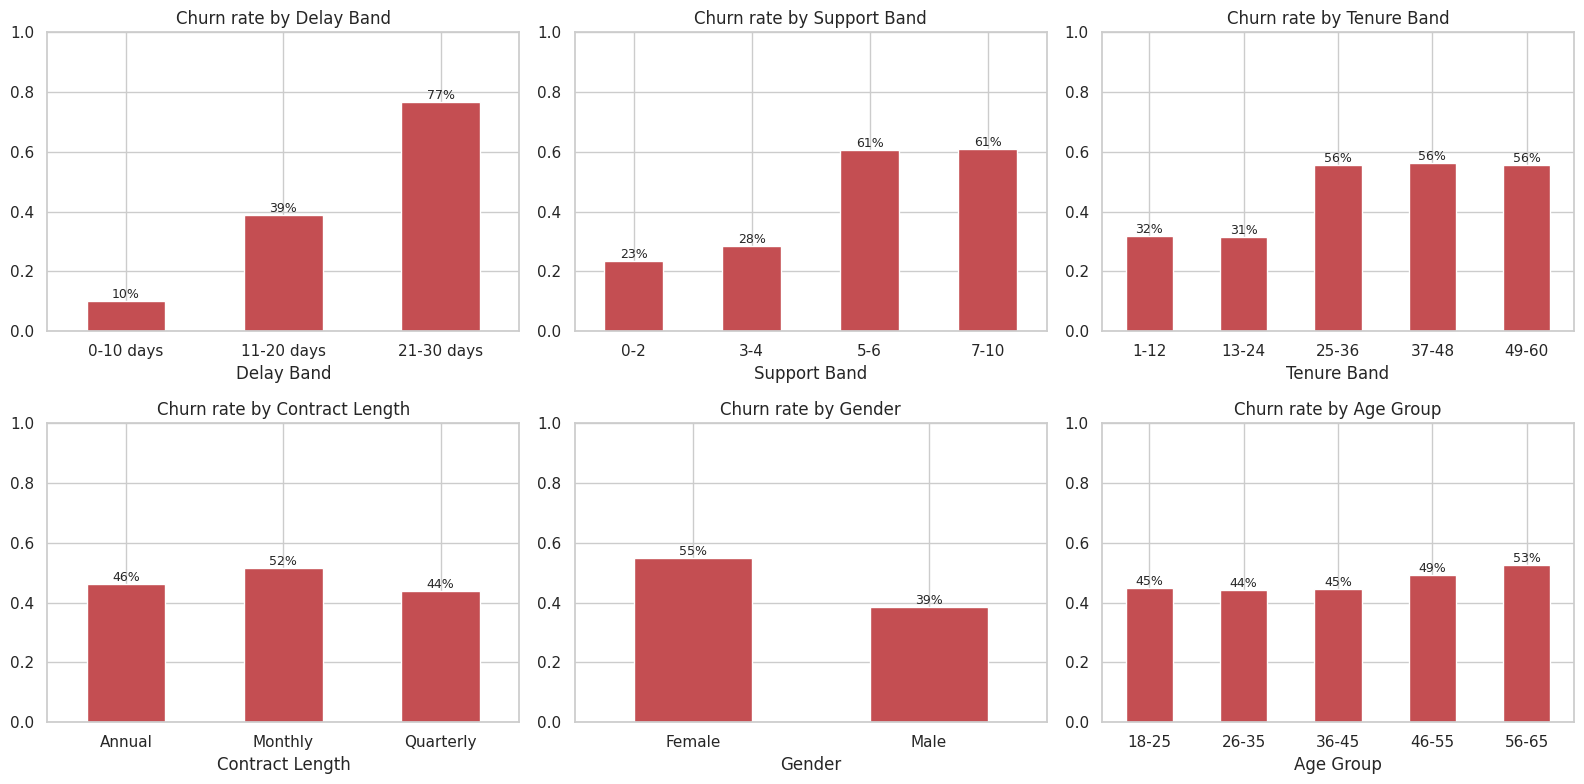

In [6]:
def rate(col):
    return df.groupby(col, observed=True).Churn.agg(['size','mean']).rename(columns={'mean':'churn_rate'}).round(3)

for c in ['Delay Band','Support Band','Tenure Band','Gender','Contract Length','Subscription Type','Age Group']:
    print(f'--- Churn by {c} ---'); print(rate(c).to_string()); print()

print('--- Churn: Gender x Contract Length ---')
print(df.pivot_table(index='Gender', columns='Contract Length', values='Churn', aggfunc='mean', observed=True).round(3).to_string())

df['High Delay'] = df['Payment Delay'] > 20
df['High Support'] = df['Support Calls'] > 4
print('\n--- Churn: High support (>4 calls) x High delay (>20 days) ---')
print(df.pivot_table(index='High Support', columns='High Delay', values='Churn', aggfunc='mean').round(3).to_string())

fig, ax = plt.subplots(2,3, figsize=(16,8))
for a, col in zip(ax.flat, ['Delay Band','Support Band','Tenure Band','Contract Length','Gender','Age Group']):
    df.groupby(col, observed=True).Churn.mean().plot.bar(ax=a, color=PALETTE['churn'], rot=0)
    a.set_title(f'Churn rate by {col}'); a.set_ylim(0,1); annotate(a)
save_fig('03_churn_drivers')


**Findings.** Payment delay is the strongest driver (10% → 39% → 77%). Support calls jump from ~25% to ~61% once customers exceed 4 calls. The two combined give 89% churn versus 5% for customers with neither. Tenure over 24 months, female gender, monthly contracts and age 46+ also carry higher churn.

## Step 6 – Satisfaction Analysis (proxies)

Avg support calls by subscription type:
Subscription Type
Basic       5.42
Premium     5.38
Standard    5.40

Avg support calls by gender:
Gender
Female    5.30
Male      5.52

Avg support calls: churned vs retained:
Churn
0    4.5
1    6.4

Churn by spend band:
             size  churn_rate
Spend Band                   
100-250     11278       0.530
251-500     18668       0.517
501-750     17122       0.432
751-1000    17306       0.432

Avg payment delay: churned vs retained:
Churn
0    12.45
1    22.33


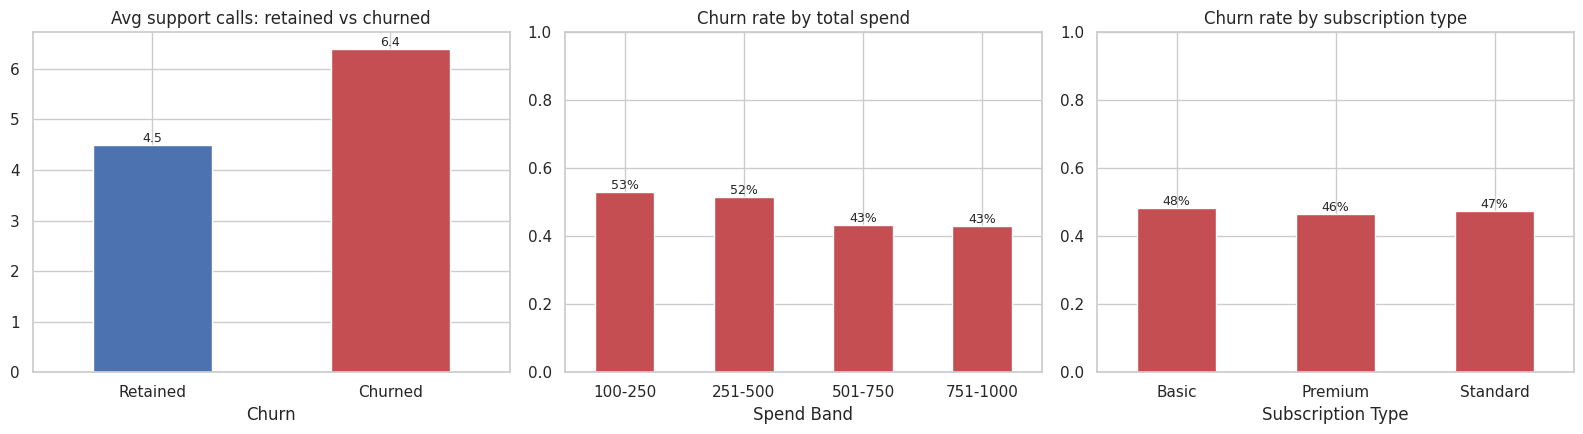

In [7]:
df['Spend Band'] = pd.cut(df['Total Spend'], [0,250,500,750,1000], labels=['100-250','251-500','501-750','751-1000'])
print('Avg support calls by subscription type:'); print(df.groupby('Subscription Type', observed=True)['Support Calls'].mean().round(2).to_string())
print('\nAvg support calls by gender:'); print(df.groupby('Gender', observed=True)['Support Calls'].mean().round(2).to_string())
print('\nAvg support calls: churned vs retained:'); print(df.groupby('Churn')['Support Calls'].mean().round(2).to_string())
print('\nChurn by spend band:'); print(rate('Spend Band').to_string())
print('\nAvg payment delay: churned vs retained:'); print(df.groupby('Churn')['Payment Delay'].mean().round(2).to_string())

fig, ax = plt.subplots(1,3, figsize=(16,4.5))
df.groupby('Churn')['Support Calls'].mean().rename({0:'Retained',1:'Churned'}).plot.bar(ax=ax[0], color=[PALETTE['base'],PALETTE['churn']], rot=0)
ax[0].set_title('Avg support calls: retained vs churned'); annotate(ax[0], '{:.1f}')
df.groupby('Spend Band', observed=True).Churn.mean().plot.bar(ax=ax[1], color=PALETTE['churn'], rot=0)
ax[1].set_title('Churn rate by total spend'); ax[1].set_ylim(0,1); annotate(ax[1])
df.groupby('Subscription Type', observed=True).Churn.mean().plot.bar(ax=ax[2], color=PALETTE['churn'], rot=0)
ax[2].set_title('Churn rate by subscription type'); ax[2].set_ylim(0,1); annotate(ax[2])
save_fig('04_satisfaction_proxies')


**Findings.** Churned customers make more support calls (~6.4 vs ~4.5). Lower spenders churn more (52-53% vs 43%). Subscription tier has almost no effect on either support contact or churn.

## Step 7 – Data Visualization (summary views)

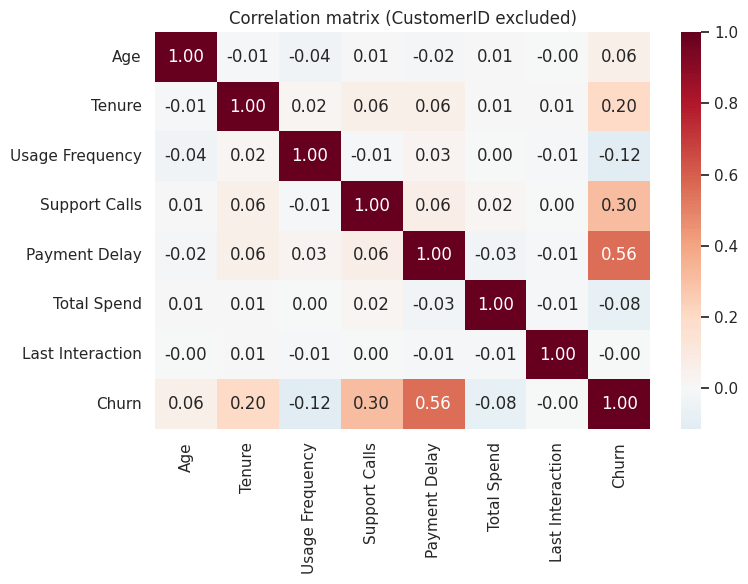

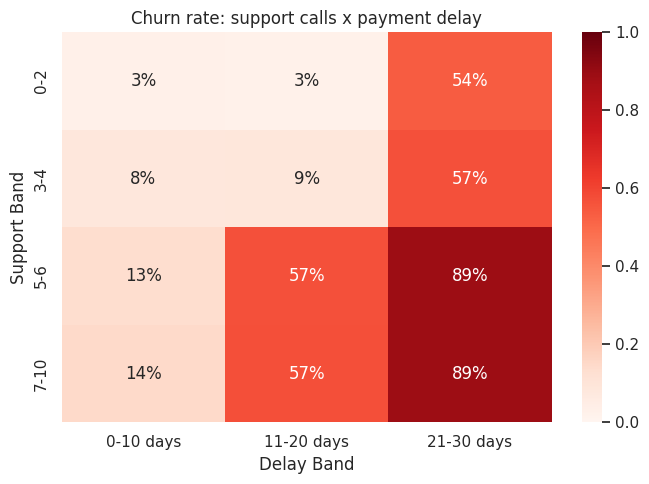

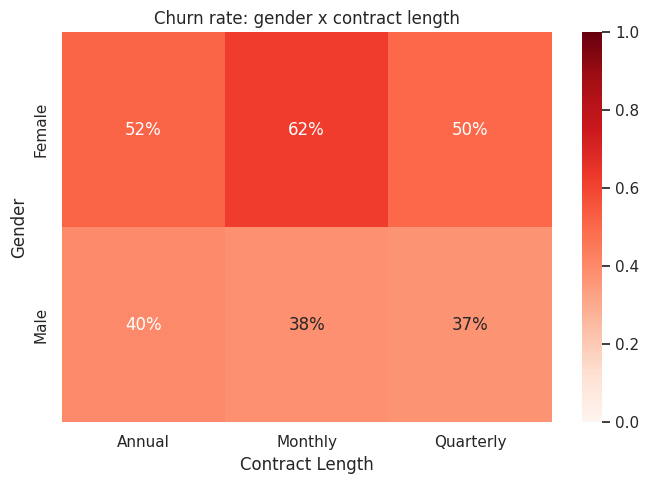

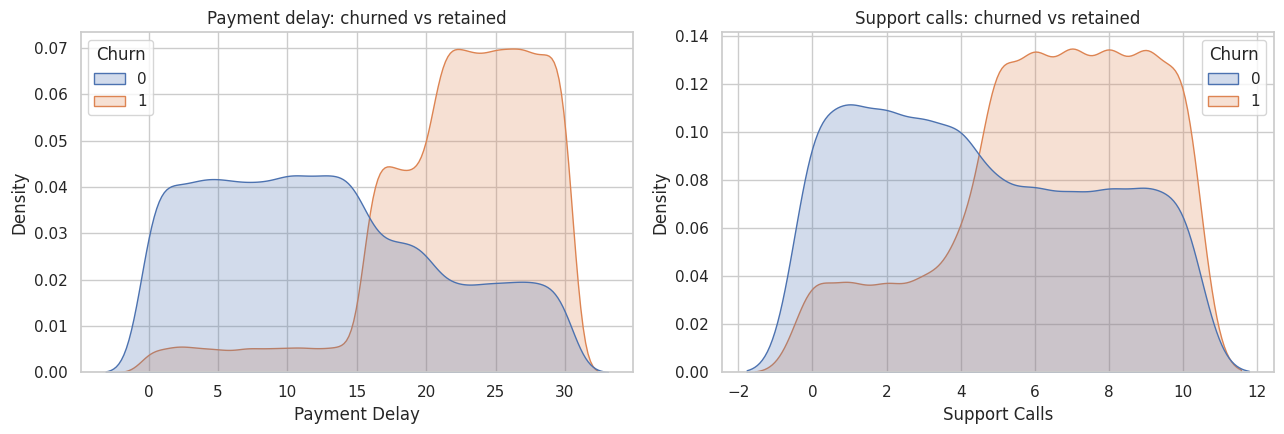

In [8]:
num = df[['Age','Tenure','Usage Frequency','Support Calls','Payment Delay','Total Spend','Last Interaction','Churn']]
plt.figure(figsize=(8,6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation matrix (CustomerID excluded)')
save_fig('05_correlation_heatmap')

plt.figure(figsize=(7,5))
hm = df.pivot_table(index='Support Band', columns='Delay Band', values='Churn', aggfunc='mean', observed=True)
sns.heatmap(hm, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=1)
plt.title('Churn rate: support calls x payment delay')
save_fig('06_support_delay_heatmap')

plt.figure(figsize=(7,5))
hm2 = df.pivot_table(index='Gender', columns='Contract Length', values='Churn', aggfunc='mean', observed=True)
sns.heatmap(hm2, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=1)
plt.title('Churn rate: gender x contract length')
save_fig('07_gender_contract_heatmap')

fig, ax = plt.subplots(1,2, figsize=(13,4.5))
sns.kdeplot(data=df, x='Payment Delay', hue='Churn', fill=True, common_norm=False, ax=ax[0]); ax[0].set_title('Payment delay: churned vs retained')
sns.kdeplot(data=df, x='Support Calls', hue='Churn', fill=True, common_norm=False, ax=ax[1], bw_adjust=1.5); ax[1].set_title('Support calls: churned vs retained')
save_fig('08_distribution_by_churn')


## Step 8 – Key Business Insights
1. **Payment delay is the dominant churn signal:** churn rises from 10% to 77% across delay bands (correlation 0.56).
2. **Heavy support contact predicts churn:** 5+ calls ≈ 61% churn vs ≈ 23-29% for ≤ 4 calls.
3. **Delay and support calls compound:** 89% churn when both are high vs 5% when both are low.
4. **Low usage (1-10) adds ≈ 12 points of churn**, a much smaller effect than billing and support issues.
5. **Customers past 24 months tenure churn more** (≈ 56% vs ≈ 32%), so loyalty is not protecting the base.
6. **Women and monthly-contract users are the highest-risk segments** (women on monthly plans ≈ 62%).
7. **Subscription tier, last-interaction recency and usage above the low band barely matter**, so tier/pricing changes are unlikely to reduce churn.

## Step 9 – Business Recommendations
1. **Fix billing friction first:** reminders, autopay, flexible due dates; intervene before the 10-day delay mark.
2. **Deploy an early-warning flag** (delay > 20 days or > 4 support calls) and route flagged customers to retention.
3. **Improve first-contact resolution** in support and follow up proactively after the 4th call.
4. **Re-engage low-usage users** with onboarding nudges and run win-back offers around the 24-month mark.
5. **Shift monthly customers to quarterly/annual plans** with incentives, and investigate why female customers churn far more.

*Caveat: findings are associations, and the ID-ordering anomaly means exact percentages may not generalise.*